<div style="background: linear-gradient(135deg, #123b5d, #1f6f8b); color: white; padding: 28px; border-radius: 12px;">
  <h1 style="margin: 0;">GBU 2301: Business Statistics</h1>
  <h2 style="margin: 8px 0 18px 0; font-weight: 400;">Week 6: Discrete Probability Distributions II</h2>
  <p style="margin: 0; font-size: 1.05em;">Fall 2026 | Dr. Omer Cayirli | Assistant Professor of Finance</p>
</div>

Required reading: Anderson et al., Statistics for Business and Economics, 15th ed., Sections 5.5–5.7

---

### Outline

* Binomial Probability Distribution
* Poisson Probability Distribution
* Hypergeometric Probability Distribution

---

### Midterm Grades (Scaled)

![Midterm grades (scaled)](../../images/midterm_scaled_scores.png)

---

### Midterm Grades (Raw)

![Midterm grades (raw)](../../images/midterm_raw_scores.png)

---

### Binomial Probability Distribution

* Two customers, each with a purchase probability of $0.40$
* Independent purchase decisions
* $X$: number of purchases

| $x$ | Outcomes | $P(X=x)$ |
|---|---|---:|
| 0 | No purchase, no purchase | $0.60^2=0.36$ |
| 1 | Purchase, no purchase; no purchase, purchase | $2(0.40)(0.60)=0.48$ |
| 2 | Purchase, purchase | $0.40^2=0.16$ |

* Two customers: manageable to list every outcome
* Ten customers: $2^{10}=1{,}024$ purchase/no-purchase sequences
* Binomial model: probabilities for the purchase count without listing every sequence

---

### Binomial Probability Distribution

Let $X$ count the number of successes in $n$ trials. A binomial model requires:

| Condition | Meaning |
|---|---|
| Fixed number of trials | The number $n$ is set before observing the outcomes. |
| Two outcomes per trial | Each trial is classified as success or failure. |
| Constant probability | The success probability $p$ is the same on every trial. |
| Independent trials | One trial's outcome does not change the probabilities for the others. |

$$X\sim\operatorname{Bin}(n,p),\qquad x=0,1,\ldots,n.$$

* “Success”: the outcome being counted
  * If $X$ counts defective items, a defect is a success in this notation.
* For example, each customer has a 40% chance of buying.
  * Knowing whether one customer buys does not change the 40% probability for another customer.

---

### Binomial Probabilities: One Sequence

* Three customers
* Independent decisions and a common purchase probability

| Number of customers, $n$ | Purchase probability, $p$ | No-purchase probability, $1-p$ |
|---:|---:|---:|
| 3 | 0.40 | 0.60 |

Let $B$ denote a purchase and $N$ no purchase. The probability of the particular sequence $(B,B,N)$ is

$$P(B,B,N)=0.40(0.40)(0.60)=0.096.$$

Exactly two purchases can occur in three ways:

| Sequence | Probability |
|---|---:|
| $(B,B,N)$ | $0.40(0.40)(0.60)=0.096$ |
| $(B,N,B)$ | $0.40(0.60)(0.40)=0.096$ |
| $(N,B,B)$ | $0.60(0.40)(0.40)=0.096$ |

$$P(X=2)=0.096+0.096+0.096=0.288.$$

The probability of one sequence is not the probability of the count.

---

### Binomial Coefficient

* $x$ successes in $n$ trials: choose the $x$ success positions.
* Remaining $n-x$ positions: failures

$$\text{Number of sequences}=\binom{n}{x}=\frac{n!}{x!(n-x)!},\qquad 0!=1.$$

For two purchases among three customers:

$$\binom{3}{2}=\frac{3!}{2!1!}=\frac{6}{2}=3.$$

Each of these sequences has probability

$$p^x(1-p)^{n-x}.$$

The sequences are mutually exclusive, so their probabilities add:

$$P(X=x)=\underbrace{\binom{n}{x}}_{\text{number of sequences}}
\underbrace{p^x(1-p)^{n-x}}_{\text{probability of each sequence}}.$$

For no successes or all successes, there is only one sequence: $\binom{n}{0}=\binom{n}{n}=1$.

---

### Binomial Probability Function

For $X\sim\operatorname{Bin}(n,p)$,

$$f(x)=P(X=x)=\binom{n}{x}p^x(1-p)^{n-x},\qquad x=0,1,\ldots,n.$$

For the three customers with $p=0.40$:

| Purchases, $x$ | Number of sequences | Probability of each sequence | $f(x)$ |
|---|---:|---:|---:|
| 0 | $\binom{3}{0}=1$ | $0.40^0(0.60)^3=0.216$ | 0.216 |
| 1 | $\binom{3}{1}=3$ | $0.40^1(0.60)^2=0.144$ | 0.432 |
| 2 | $\binom{3}{2}=3$ | $0.40^2(0.60)^1=0.096$ | 0.288 |
| 3 | $\binom{3}{3}=1$ | $0.40^3(0.60)^0=0.064$ | 0.064 |
| Total | 8 | | 1.000 |

* Next graphs: fixed $n=6$, different values of $p$
* Same possible counts; different probabilities

---

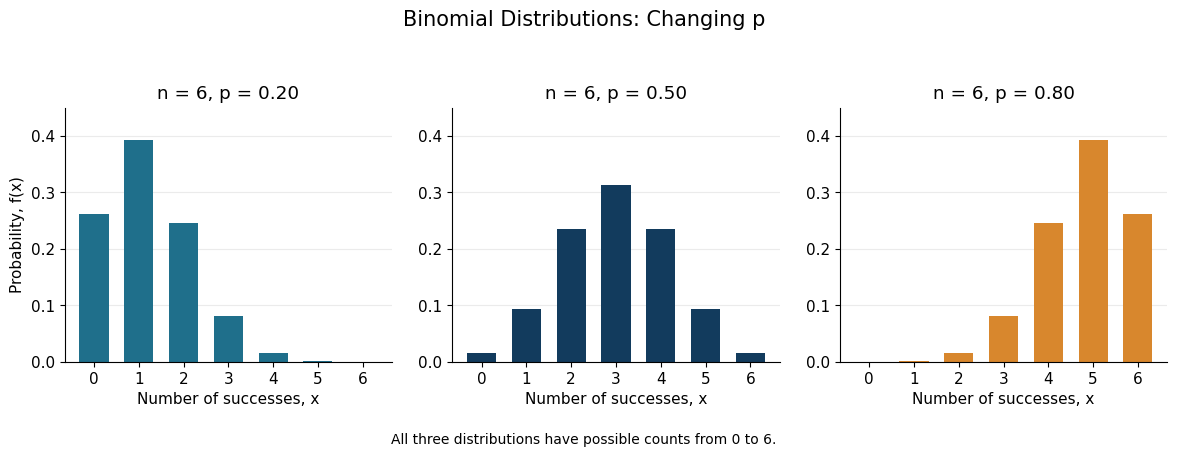

In [1]:
from math import comb
import numpy as np
import matplotlib.pyplot as plt

trial_count = 6
counts = np.arange(trial_count + 1)
success_probabilities = [0.20, 0.50, 0.80]
colors = ["#1f6f8b", "#123b5d", "#d8872d"]

with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharex=True, sharey=True)
    for ax, p, color in zip(axes, success_probabilities, colors):
        probabilities = np.array([
            comb(trial_count, int(x)) * p**x * (1-p)**(trial_count-x)
            for x in counts
        ])
        assert np.isclose(probabilities.sum(), 1)
        ax.bar(counts, probabilities, width=0.65, color=color)
        ax.set(title=f"n = {trial_count}, p = {p:.2f}",
               xlabel="Number of successes, x", xticks=counts,
               ylim=(0, 0.45))
        ax.tick_params(labelleft=True)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Probability, f(x)")
    fig.suptitle("Binomial Distributions: Changing p", fontsize=15)
    fig.text(0.5, 0.015, "All three distributions have possible counts from 0 to 6.",
             ha="center", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 0.93))
    plt.show()

### Binomial Probabilities: Sales

A broker contacts five potential customers.

* Independent decisions
* Same sale probability for every contact

| Contacts, $n$ | Sale probability, $p$ | Random variable, $X$ |
|---:|---:|---|
| 5 | 0.40 | Number of sales |

The probability of exactly three sales is

$$P(X=3)=\binom{5}{3}(0.40)^3(0.60)^2
=\frac{5!}{3!2!}(0.064)(0.36)=10(0.064)(0.36)=0.2304.$$

Applying the same formula to every possible count gives:

| Sales, $x$ | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---:|---:|---:|---:|---:|---:|
| $f(x)$ | 0.07776 | 0.25920 | 0.34560 | 0.23040 | 0.07680 | 0.01024 |

$$\sum_{x=0}^{5}f(x)=1.$$

The individual sale probability $0.40$ is not the probability of exactly three sales.

---

### Cumulative and Complementary Probabilities

For the five contacts with $p=0.40$:

| Event | Calculation | Probability |
|---|---|---:|
| At most one sale | $P(X\leq1)=f(0)+f(1)$ | $0.07776+0.25920=0.33696$ |
| At least two sales | $P(X\geq2)=1-P(X\leq1)$ | $1-0.33696=0.66304$ |
| More than two sales | $P(X>2)=1-P(X\leq2)$ | $1-0.68256=0.31744$ |
| Between two and four sales, inclusive | $P(2\leq X\leq4)=1-f(0)-f(1)-f(5)$ | $0.65280$ |

For an integer count and integer $k$,

$$P(X\geq k)=1-P(X\leq k-1),\qquad P(X>k)=1-P(X\leq k).$$

For an inclusive interval,

$$P(a\leq X\leq b)=\sum_{x=a}^{b}f(x).$$

Check which boundary values belong to the event before adding or subtracting probabilities.

---

### Binomial Probabilities: Sales

$X\sim\operatorname{Bin}(5,0.40)$: at most 1 sale.

$$f(x)=\binom{5}{x}(0.40)^x(0.60)^{5-x}.$$

$$P(X\leq 1)=f(0)+f(1).$$

| Sales, $x$ | Calculation of $f(x)$ | Probability |
|---|---|---:|
| 0 | $\binom{5}{0}(0.40)^{0}(0.60)^{5}=1(0.40)^{0}(0.60)^{5}$ | 0.07776 |
| 1 | $\binom{5}{1}(0.40)^{1}(0.60)^{4}=5(0.40)^{1}(0.60)^{4}$ | 0.25920 |

$$P(X\leq 1)=0.07776+0.25920=0.33696=33.696\%.$$

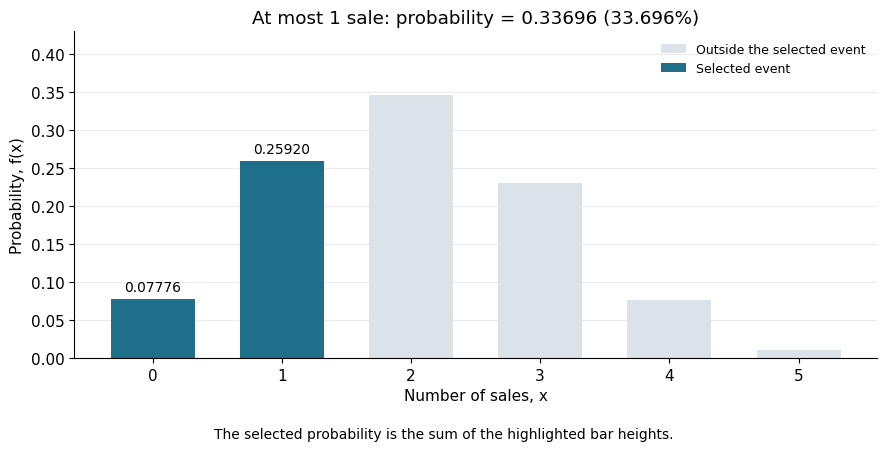

In [1]:
from math import comb
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def sales_probability_explorer():
    n, p = 5, 0.40
    values = list(range(n + 1))
    probabilities = [comb(n, x) * p**x * (1-p)**(n-x) for x in values]

    formulation = widgets.Dropdown(
        options=[
            ("At most k sales (k or fewer)", "le"),
            ("Fewer than k sales", "lt"),
            ("Exactly k sales", "eq"),
            ("At least k sales (k or more)", "ge"),
            ("More than k sales", "gt"),
            ("Between a and b sales (including both)", "between"),
            ("Outside a to b sales (below a or above b)", "outside"),
        ],
        value="le", description="Event:",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="600px", max_width="100%"),
    )
    cutoff = widgets.IntSlider(
        value=1, min=0, max=n, description="Sales (k):",
        continuous_update=False, style={"description_width": "initial"},
    )
    interval = widgets.IntRangeSlider(
        value=(2, 4), min=0, max=n, description="Range (a, b):",
        continuous_update=False, style={"description_width": "initial"},
        layout=widgets.Layout(display="none"),
    )
    controls = widgets.VBox([formulation, cutoff, interval])
    display(controls)
    calculation_display = display(Markdown(""), display_id=True)
    graph_display = display(Markdown(""), display_id=True)

    def update(change=None):
        kind, k = formulation.value, cutoff.value
        a, b = interval.value
        is_range = kind in ("between", "outside")
        cutoff.layout.display = "none" if is_range else ""
        interval.layout.display = "" if is_range else "none"
        sale_word = "sale" if k == 1 else "sales"
        events = {
            "le": ([x for x in values if x <= k], rf"X\leq {k}", f"At most {k} {sale_word}"),
            "lt": ([x for x in values if x < k], rf"X<{k}", f"Fewer than {k} {sale_word}"),
            "eq": ([x for x in values if x == k], rf"X={k}", f"Exactly {k} {sale_word}"),
            "ge": ([x for x in values if x >= k], rf"X\geq {k}", f"At least {k} {sale_word}"),
            "gt": ([x for x in values if x > k], rf"X>{k}", f"More than {k} {sale_word}"),
            "between": ([x for x in values if a <= x <= b], rf"{a}\leq X\leq {b}",
                        f"Between {a} and {b} sales, inclusive"),
            "outside": ([x for x in values if x < a or x > b], rf"X<{a}\ \mathrm{{or}}\ X>{b}",
                        f"Fewer than {a} or more than {b} sales"),
        }
        selected, event, title = events[kind]
        excluded = [x for x in values if x not in selected]
        result = sum(probabilities[x] for x in selected)
        use_complement = len(excluded) < len(selected)
        terms = excluded if use_complement else selected
        lines = [
            "### Binomial Probabilities: Sales",
            rf"$X\sim\operatorname{{Bin}}(5,0.40)$: {title.lower()}.",
            r"$$f(x)=\binom{5}{x}(0.40)^x(0.60)^{5-x}.$$",
        ]
        if not selected:
            lines.append("No possible sales count satisfies this event.")
        elif not excluded:
            lines.append("Every possible sales count satisfies this event.")
        else:
            symbolic_sum = "+".join(rf"f({x})" for x in terms)
            expression = rf"1-\left[{symbolic_sum}\right]" if use_complement else symbolic_sum
            lines.append(rf"$$P({event})={expression}.$$")
            if use_complement:
                lines.append("Subtract the probabilities of the excluded counts from one.")
            lines.extend([
                "",
                "| Sales, $x$ | Calculation of $f(x)$ | Probability |",
                "|---|---|---:|",
            ])
            for x in terms:
                formula = rf"\binom{{5}}{{{x}}}(0.40)^{{{x}}}(0.60)^{{{5-x}}}"
                evaluated = rf"{comb(5, x)}(0.40)^{{{x}}}(0.60)^{{{5-x}}}"
                lines.append(f"| {x} | $" + formula + "=" + evaluated +
                             f"$ | {probabilities[x]:.5f} |")
            lines.append("")
            numbers = "+".join(f"{probabilities[x]:.5f}" for x in terms)
            numeric_expression = rf"1-\left[{numbers}\right]" if use_complement else numbers
            lines.append(rf"$$P({event})={numeric_expression}={result:.5f}={100*result:.3f}\%.$$")
        if not terms:
            lines.append(rf"$$P({event})={result:.5f}={100*result:.3f}\%.$$")
        calculation_display.update(Markdown("\n\n".join(lines[:3]) + "\n\n" +
                                             "\n".join(lines[3:])))

        with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                             "axes.spines.right": False}):
            fig, ax = plt.subplots(figsize=(9, 4.5))
            ax.bar(values, probabilities, width=0.65, color="#dce3e8",
                   label="Outside the selected event")
            if selected:
                bars = ax.bar(selected, [probabilities[x] for x in selected],
                              width=0.65, color="#1f6f8b", label="Selected event")
                ax.bar_label(bars, labels=[f"{probabilities[x]:.5f}" for x in selected],
                             padding=4, fontsize=10)
            ax.set(title=f"{title}: probability = {result:.5f} ({100*result:.3f}%)",
                   xlabel="Number of sales, x", ylabel="Probability, f(x)",
                   xticks=values, ylim=(0, 0.43))
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)
            ax.legend(frameon=False, fontsize=9, loc="upper right")
            fig.text(0.5, 0.01,
                     "The selected probability is the sum of the highlighted bar heights.",
                     ha="center", fontsize=10)
            fig.tight_layout(rect=(0, 0.05, 1, 1))
            graph_display.update(fig)
            plt.close(fig)

    for control in (formulation, cutoff, interval):
        control.observe(update, names="value")
    update()
    return controls

sales_controls = sales_probability_explorer()

### Exercise 1

Delta Deliveries handles four parcels. Assume that on-time deliveries are independent and each parcel has the same probability of arriving on time.

| Parcels | Probability of on-time delivery per parcel |
|---:|---:|
| 4 | 0.70 |

a. Find the probability that exactly three parcels arrive on time.

b. Find the probability that at least three parcels arrive on time.

c. Find the probability that at most one parcel arrives on time.

---


### Exercise 2

Gamma Components tests the next six items from a production line. Assume that defect statuses are independent and the defect probability stays constant.

| Items tested | Defect probability per item |
|---:|---:|
| 6 | 0.10 |

A worksheet reports a probability of $0.006561$ that exactly two of the six items are defective.

a. Check the worksheet entry. Explain what calculation could have produced it and give the correct probability.

b. The six-item batch is sent for rework if at least two items are defective. Find the probability of rework.

---

### Binomial Mean and Variance

For trial $i$, let $I_i=1$ for success and $I_i=0$ for failure. The total number of successes is

$$X=I_1+I_2+\cdots+I_n.$$

For one trial, $P(I_i=1)=p$ and $P(I_i=0)=1-p$.

$$E(I_i)=0(1-p)+1(p)=p.$$

$$\begin{aligned}
\operatorname{Var}(I_i)
&=(0-p)^2(1-p)+(1-p)^2p\\
&=p^2(1-p)+p(1-p)^2\\
&=p(1-p)\big[p+(1-p)\big]=p(1-p).
\end{aligned}$$

Thus,

$$E(X)=\sum_{i=1}^{n}E(I_i)=\underbrace{p+\cdots+p}_{n\text{ terms}}=np.$$

For the variance, independence makes every covariance between different trials zero:

$$\begin{aligned}
\operatorname{Var}(X)
&=\sum_{i=1}^{n}\operatorname{Var}(I_i)
  +2\sum_{i<j}\operatorname{Cov}(I_i,I_j)\\
&=np(1-p)+0.
\end{aligned}$$

$$\mu=np,\qquad \sigma^2=np(1-p),\qquad \sigma=\sqrt{np(1-p)}.$$

For the broker's five contacts:

$$\mu=5(0.40)=2\text{ sales},\quad
\sigma^2=5(0.40)(0.60)=1.20\text{ sales}^2,\quad
\sigma=\sqrt{1.20}\approx1.095\text{ sales}.$$

---

### Bernoulli Probability Distribution

* Binomial: number of successes across $n$ trials
* Bernoulli: outcome of a single success/failure trial

Record that single trial using $I$:

| Outcome | $I$ | Probability |
|---|---:|---:|
| Failure | 0 | $1-p$ |
| Success | 1 | $p$ |

A Bernoulli random variable is a binomial random variable with $n=1$:

$$I\sim\operatorname{Bin}(1,p).$$

The variables $I_1,\ldots,I_n$ in the preceding binomial calculation are Bernoulli variables. Their mean and variance explain the terms $p$ and $p(1-p)$ used there.

---


### Bernoulli Mean and Variance

Represent one trial by $I$, where $I=1$ for success and $I=0$ for failure. This is a Bernoulli random variable.

| $i$ | $P(I=i)$ | $iP(I=i)$ | $i^2P(I=i)$ |
|---|---:|---:|---:|
| 0 | $1-p$ | 0 | 0 |
| 1 | $p$ | $p$ | $p$ |

$$E(I)=0(1-p)+1(p)=p.$$

Since $I^2=I$ for both possible outcomes,

$$E(I^2)=0^2(1-p)+1^2p=p.$$

Using the alternative variance formula,

$$\operatorname{Var}(I)=E(I^2)-[E(I)]^2=p-p^2=p(1-p).$$

---

### Bernoulli Distribution: Examples

| Single trial | $I=1$ | $I=0$ | Success probability, $p$ |
|---|---|---|---:|
| One customer | Buys | Does not buy | 0.40 |
| One parcel | Arrives on time | Arrives late | 0.70 |

For the customer:

$$E(I)=0(0.60)+1(0.40)=0.40,$$
$$\operatorname{Var}(I)=0.40(1-0.40)=0.24.$$

For the parcel:

$$E(I)=0(0.30)+1(0.70)=0.70,$$
$$\operatorname{Var}(I)=0.70(1-0.70)=0.21.$$

Each trial produces either 0 or 1. The mean describes the long-run average across repeated trials.

---


### Sales and Net Profit

Retain the broker's sales count $X\sim\operatorname{Bin}(5,0.40)$.

| Item | Amount |
|---|---:|
| Net revenue per sale, after sale-related costs | 80 MAD |
| Fixed cost of contacting the five customers | 120 MAD |

Net profit is $Y=80X-120$. Using $E(X)=2$ and $\operatorname{Var}(X)=1.20$:

$$E(Y)=80E(X)-120=80(2)-120=40\text{ MAD}.$$

$$\operatorname{Var}(Y)=80^2(1.20)=7{,}680\text{ MAD}^2,$$
$$\sigma_Y=80\sqrt{1.20}\approx87.64\text{ MAD}.$$

A loss occurs when

$$80X-120<0\quad\Rightarrow\quad X<1.5.$$

Because $X$ is an integer,

$$P(Y<0)=P(X\leq1)=0.33696.$$

Positive expected profit does not rule out a substantial probability of loss.

---

### Exercise 3

A sales team can choose one of two campaigns.

* Within each campaign: independent decisions and a constant sale probability
* All campaign costs included below

| Item | Campaign Beta | Campaign Gamma |
|---|---:|---:|
| Number of contacts | 4 | 8 |
| Sale probability per contact | 0.50 | 0.25 |
| Net revenue per sale | 80 MAD | 80 MAD |
| Fixed campaign cost | 120 MAD | 120 MAD |

a. Calculate expected net profit and its standard deviation for each campaign.

b. A campaign is acceptable only if expected net profit is at least 30 MAD and the probability of a nonnegative net profit is at least 65%. Which campaign, if either, meets both requirements? Support the decision with calculations.

---

### Poisson Probability Distribution

A Poisson random variable counts occurrences over a specified interval of time or space.

| Situation | Random variable |
|---|---|
| Calls reaching a support desk | Number of calls in 30 minutes |
| Flaws in a cable | Number of flaws in 250 metres |
| Printing marks on a sheet | Number of marks in one square metre |

Model assumptions:

* Constant average rate over the interval
* Independent counts in non-overlapping intervals
* Individual occurrences
  * In a sufficiently short interval, two or more arrivals are negligible relative to one.

The possible counts are $0,1,2,\ldots$, with no fixed upper bound.

A count is not automatically Poisson. Potential violations:

* Scheduled arrivals
* Groups arriving together
* Substantial changes in the arrival rate

---

### Poisson Probability Function

Let $\mu$ be the expected number of occurrences in the interval being studied.

$$X\sim\operatorname{Poisson}(\mu),\qquad
f(x)=P(X=x)=\frac{\mu^x e^{-\mu}}{x!},\quad x=0,1,2,\ldots.$$

* $e\approx2.71828$ and $0!=1$
* Use the calculator's $e^z$ function, not a rounded value of $e$.

* $\lambda$: constant occurrence rate per unit of time, length, or area
* $t$: interval size, in units matching $\lambda$

$$\mu=\lambda t.$$

Beta Support receives calls according to a Poisson process:

| Rate | Interval of interest | Expected count, $\mu$ |
|---|---|---:|
| 6 calls per hour | 30 minutes $=0.5$ hour | $6(0.5)=3$ |

Therefore, the number of calls in 30 minutes has distribution $\operatorname{Poisson}(3)$, not $\operatorname{Poisson}(6)$.

---

### Poisson Probabilities: Calls

For Beta Support's 30-minute interval, $\mu=3$.

* Exactly four calls:

$$P(X=4)=\frac{3^4e^{-3}}{4!}
=\frac{81e^{-3}}{24}\approx0.168031.$$

* No calls:

$$P(X=0)=\frac{3^0e^{-3}}{0!}=e^{-3}\approx0.049787.$$

* At least one call:

$$P(X\geq1)=1-P(X=0)=1-e^{-3}\approx0.950213.$$

* At most one call:

$$P(X\leq1)=P(X=0)+P(X=1)
=e^{-3}+3e^{-3}=4e^{-3}\approx0.199148.$$

An average of three calls does not mean that three is the largest possible count.

---

### Poisson Probabilities: Time Intervals

Keep the arrival rate at six calls per hour. For each interval, let $X$ count calls during that interval.

| Interval | Length in hours | $\mu$ | Probability of no calls |
|---|---:|---:|---:|
| 10 minutes | $1/6$ | $6(1/6)=1$ | $e^{-1}\approx0.367879$ |
| 30 minutes | $1/2$ | $6(1/2)=3$ | $e^{-3}\approx0.049787$ |
| 60 minutes | 1 | $6(1)=6$ | $e^{-6}\approx0.002479$ |

* Expected count: proportional to interval length
* Probabilities: not proportional to interval length

For example,

$$P(\text{no calls in 60 minutes})=e^{-6}
=(e^{-3})^2,$$

* No calls in 60 minutes requires no calls in both 30-minute intervals.
* Non-overlapping intervals: independent counts

Doubling the interval does not double the probability of no calls.

---

### Poisson Probabilities: Length

Gamma Cables models cable flaws by a Poisson process.

* Constant flaw rate
* Independent counts on non-overlapping lengths

| Average flaw rate | Length inspected |
|---:|---:|
| 0.8 flaws per 100 metres | 250 metres |

For $X$, the number of flaws in the inspected length,

$$\mu=\frac{0.8\text{ flaws}}{100\text{ metres}}(250\text{ metres})=2.$$

The probability of no flaws is

$$P(X=0)=e^{-2}\approx0.135335.$$

The probability of at least two flaws is

$$\begin{aligned}
P(X\geq2)
&=1-P(X=0)-P(X=1)\\
&=1-e^{-2}-2e^{-2}\\
&=1-3e^{-2}\approx0.593994.
\end{aligned}$$

The exposure is cable length rather than time; the same probability function applies.

---

### Poisson Probabilities: Calls

Beta Support: 6 calls per hour. At most 1 call in 30 minutes.

$$\mu=6\left(\frac{30}{60}\right)=3,\qquad X\sim\operatorname{Poisson}(3).$$

$$f(x)=\frac{3^x e^{-3}}{x!}.$$

$$P(X\leq 1)=\sum_{x=0}^{1}f(x).$$

| Calls, $x$ | Calculation of $f(x)$ | Probability |
|---|---|---:|
| 0 | $\frac{3^{0}e^{-3}}{0!}$ | $0.0497871$ |
| 1 | $\frac{3^{1}e^{-3}}{1!}$ | $0.149361$ |

$$P(X\leq 1)\approx 0.0497871+0.149361\approx 0.199148=19.9148\%.$$
Results use unrounded probabilities.

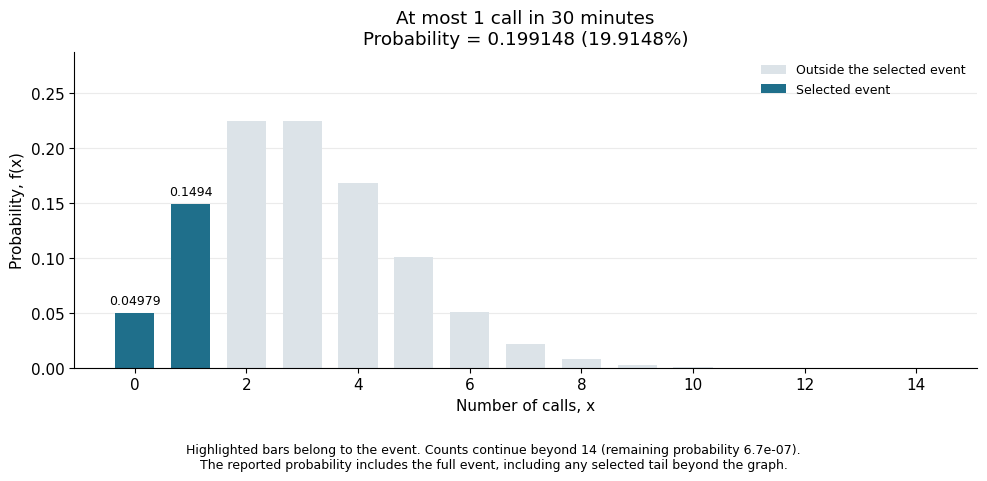

In [3]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def poisson_probability_explorer():
    from math import fsum
    from scipy.stats import poisson

    rate = 6
    formulation = widgets.Dropdown(
        options=[
            ("At most k calls (k or fewer)", "le"),
            ("Fewer than k calls", "lt"),
            ("Exactly k calls", "eq"),
            ("At least k calls (k or more)", "ge"),
            ("More than k calls", "gt"),
            ("Between a and b calls (including both)", "between"),
            ("Outside a to b calls (below a or above b)", "outside"),
        ],
        value="le", description="Event:",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="600px", max_width="100%"),
    )
    minutes = widgets.IntSlider(
        value=30, min=5, max=120, step=5, description="Minutes:",
        continuous_update=False, style={"description_width": "initial"},
    )
    cutoff = widgets.IntSlider(
        value=1, min=0, max=20, description="Calls (k):",
        continuous_update=False, style={"description_width": "initial"},
    )
    interval = widgets.IntRangeSlider(
        value=(2, 4), min=0, max=20, description="Range (a, b):",
        continuous_update=False, style={"description_width": "initial"},
        layout=widgets.Layout(display="none"),
    )
    controls = widgets.VBox([formulation, minutes, cutoff, interval])
    display(controls)
    calculation_display = display(Markdown(""), display_id=True)
    graph_display = display(Markdown(""), display_id=True)

    def tex_number(value):
        text = f"{value:.6g}"
        if "e" in text:
            mantissa, exponent = text.split("e")
            return rf"{mantissa}\times10^{{{int(exponent)}}}"
        return text

    def update(change=None):
        kind, k = formulation.value, cutoff.value
        a, b = interval.value
        mu = rate * minutes.value / 60
        is_range = kind in ("between", "outside")
        cutoff.layout.display = "none" if is_range else ""
        interval.layout.display = "" if is_range else "none"
        call_word = "call" if k == 1 else "calls"
        events = {
            "le": (0, k, False, rf"X\leq {k}", f"At most {k} {call_word}"),
            "lt": (0, k-1, False, rf"X<{k}", f"Fewer than {k} {call_word}"),
            "eq": (k, k, False, rf"X={k}", f"Exactly {k} {call_word}"),
            "ge": (0, k-1, True, rf"X\geq {k}", f"At least {k} {call_word}"),
            "gt": (0, k, True, rf"X>{k}", f"More than {k} {call_word}"),
            "between": (a, b, False, rf"{a}\leq X\leq {b}",
                        f"Between {a} and {b} calls, inclusive"),
            "outside": (a, b, True, rf"X<{a}\ \mathrm{{or}}\ X>{b}",
                        f"Fewer than {a} or more than {b} calls"),
        }
        lower, upper, complement, event, title = events[kind]
        terms = list(range(lower, upper+1))

        # Upper tails include all possible counts, not only the bars displayed.
        if kind == "ge":
            result = float(poisson.sf(k-1, mu))
        elif kind == "gt":
            result = float(poisson.sf(k, mu))
        elif kind == "outside":
            result = float(poisson.cdf(a-1, mu) + poisson.sf(b, mu))
        else:
            result = fsum(float(poisson.pmf(x, mu)) for x in terms)

        lines = [
            "### Poisson Probabilities: Calls",
            f"Beta Support: {rate} calls per hour. {title} in {minutes.value} minutes.",
            rf"$$\mu={rate}\left(\frac{{{minutes.value}}}{{60}}\right)={mu:g},"
            rf"\qquad X\sim\operatorname{{Poisson}}({mu:g}).$$",
            rf"$$f(x)=\frac{{{mu:g}^x e^{{-{mu:g}}}}}{{x!}}.$$",
        ]
        if not terms:
            lines.append("Every possible count satisfies this event." if complement
                         else "No possible count satisfies this event.")
        else:
            symbolic_sum = (rf"f({lower})" if len(terms) == 1 else
                            rf"\sum_{{x={lower}}}^{{{upper}}}f(x)")
            expression = rf"1-\left[{symbolic_sum}\right]" if complement else symbolic_sum
            lines.append(rf"$$P({event})={expression}.$$")
            if complement:
                lines.append("Subtract the probabilities of the excluded counts from one.")
            lines.extend(["", "| Calls, $x$ | Calculation of $f(x)$ | Probability |",
                          "|---|---|---:|"])
            # Keep long ranges readable without dropping any terms from the result.
            shown = terms if len(terms) <= 6 else terms[:3] + [None] + terms[-2:]
            for x in shown:
                if x is None:
                    lines.append("| ... | ... | ... |")
                else:
                    formula = rf"\frac{{{mu:g}^{{{x}}}e^{{-{mu:g}}}}}{{{x}!}}"
                    value = tex_number(float(poisson.pmf(x, mu)))
                    lines.append(f"| {x} | $" + formula + "$ | $" + value + "$ |")
            lines.append("")
            if len(terms) <= 6:
                numbers = "+".join(tex_number(float(poisson.pmf(x, mu))) for x in terms)
                arithmetic = rf"1-\left[{numbers}\right]" if complement else numbers
                lines.append(rf"$$P({event})\approx {arithmetic}"
                             rf"\approx {tex_number(result)}={tex_number(100*result)}\%.$$")
            else:
                lines.append(rf"$$P({event})\approx {tex_number(result)}"
                             rf"={tex_number(100*result)}\%.$$")
                lines.append(f"All {len(terms)} terms in the sum are included; intermediate rows are omitted.")
            lines.append("Results use unrounded probabilities.")
        if not terms:
            lines.append(rf"$$P({event})={result:g}={100*result:g}\%.$$")

        calculation_display.update(Markdown("\n\n".join(lines[:4]) + "\n\n" +
                                             "\n".join(lines[4:])))
        last = max(8, int(poisson.ppf(1-1e-6, mu)), b if is_range else k)
        values = list(range(last+1))
        probabilities = [float(poisson.pmf(x, mu)) for x in values]
        selected = [x for x in values if (lower <= x <= upper) != complement]
        omitted_tail = float(poisson.sf(last, mu))

        with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                             "axes.spines.right": False}):
            fig, ax = plt.subplots(figsize=(10, 4.8))
            ax.bar(values, probabilities, width=0.70, color="#dce3e8",
                   label="Outside the selected event")
            if selected:
                bars = ax.bar(selected, [probabilities[x] for x in selected],
                              width=0.70, color="#1f6f8b", label="Selected event")
                if len(selected) <= 6:
                    ax.bar_label(bars, labels=[f"{probabilities[x]:.4g}" for x in selected],
                                 padding=4, fontsize=9)
            ax.set(title=f"{title} in {minutes.value} minutes\n"
                         f"Probability = {result:.6g} ({100*result:.6g}%)",
                   xlabel="Number of calls, x", ylabel="Probability, f(x)",
                   xticks=range(0, last+1, 1 if last <= 12 else 2),
                   ylim=(0, max(probabilities)*1.28))
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)
            ax.legend(frameon=False, fontsize=9, loc="upper right")
            fig.text(0.5, 0.01,
                     f"Highlighted bars belong to the event. Counts continue beyond {last} "
                     f"(remaining probability {omitted_tail:.2g}).\n"
                     "The reported probability includes the full event, including any selected tail beyond the graph.",
                     ha="center", fontsize=9)
            fig.tight_layout(rect=(0, 0.09, 1, 1))
            graph_display.update(fig)
            plt.close(fig)

    for control in (formulation, minutes, cutoff, interval):
        control.observe(update, names="value")
    update()
    return controls

poisson_controls = poisson_probability_explorer()

### Poisson Mean and Variance

For $X\sim\operatorname{Poisson}(\mu)$,

$$E(X)=\mu,\qquad \operatorname{Var}(X)=\mu,\qquad \sigma=\sqrt{\mu}.$$

* Mean and variance: same numerical value, different units

For Beta Support:

| Interval | Mean (calls) | Variance (calls squared) | SD (calls) |
|---|---:|---:|---:|
| 10 minutes | 1 | 1 | 1 |
| 30 minutes | 3 | 3 | $\sqrt{3}\approx1.732$ |
| 60 minutes | 6 | 6 | $\sqrt{6}\approx2.449$ |

From 30 to 60 minutes:

* Mean and variance: double
* Standard deviation: multiplied by $\sqrt{2}$

$$\frac{\sqrt{6}}{\sqrt{3}}=\sqrt{2}.$$

Equality of the theoretical mean and variance is a property of the Poisson model, not a rule that every observed set of counts must satisfy exactly.

---

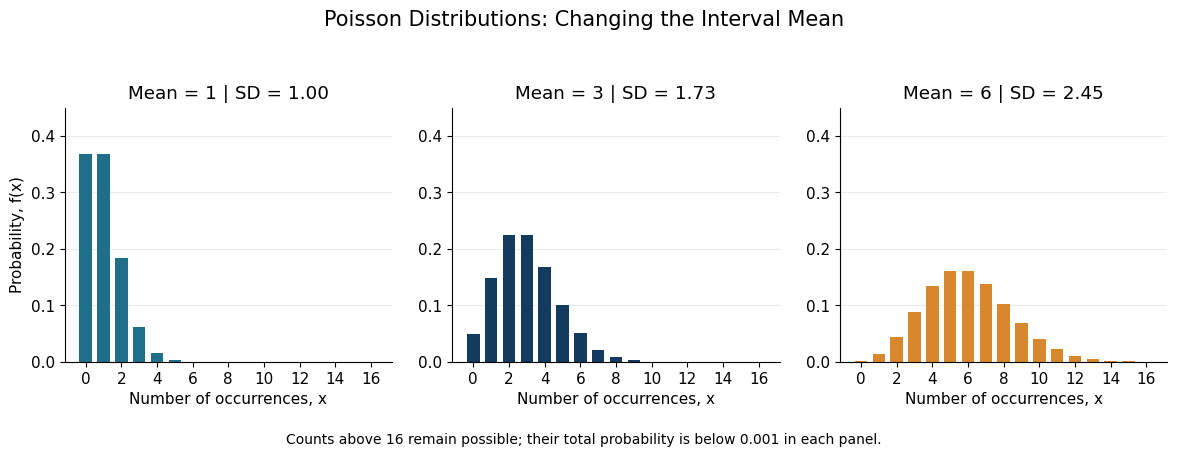

In [4]:
from math import exp, factorial
import numpy as np
import matplotlib.pyplot as plt

counts = np.arange(17)
interval_means = [1, 3, 6]
colors = ["#1f6f8b", "#123b5d", "#d8872d"]

with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharex=True, sharey=True)
    for ax, mean, color in zip(axes, interval_means, colors):
        probabilities = np.array([
            mean**int(x) * exp(-mean) / factorial(int(x)) for x in counts
        ])
        assert probabilities.sum() <= 1 + 1e-12
        assert 1 - probabilities.sum() < 0.001
        ax.bar(counts, probabilities, width=0.70, color=color)
        ax.set(title=f"Mean = {mean} | SD = {mean**0.5:.2f}",
               xlabel="Number of occurrences, x",
               xticks=np.arange(0, 17, 2), ylim=(0, 0.45))
        ax.tick_params(labelleft=True)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Probability, f(x)")
    fig.suptitle("Poisson Distributions: Changing the Interval Mean", fontsize=15)
    fig.text(0.5, 0.015,
             "Counts above 16 remain possible; their total probability is below 0.001 in each panel.",
             ha="center", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 0.93))
    plt.show()

### Exercise 4

Calls reach Delta Reservations according to a Poisson process with a constant rate.

| Average arrival rate |
|---:|
| 12 calls per hour |

a. Find the probability that at most one call arrives during a ten-minute interval.

b. Find the probability that each of two consecutive five-minute intervals contains at least one call.

c. Find the probability that at least one call arrives during the full ten minutes. Explain why this differs from part (b).

---

### Exercise 5

Epsilon Couriers receives collection requests according to a Poisson process.

* Requests in each booking window: collected together after the window closes
* No requests carried over from earlier windows

| Arrival rate | Booking window |
|---:|---:|
| 8 requests per hour | 15 minutes |

Before a window begins, the firm chooses one vehicle:

| Vehicle capacity (requests) | Vehicle fee per window (MAD) |
|---:|---:|
| 3 | 20 |
| 4 | 27 |
| 5 | 36 |

* Requests above capacity: all excess requests collected by an external provider
* One fixed additional fee of 50 MAD, regardless of the number of excess requests
* No other costs

Choose the vehicle with the lowest expected total cost among those requiring the external provider in no more than 10% of windows. Support the choice numerically. Would the choice change if the limit were 15%?

---

### Sampling Without Replacement

Beta Services:

* Team of ten: four certified employees and six non-certified employees
* Random selection of three different employees
* Every group of three equally likely

Let $X$ count certified employees in the selected group.

| Selection | Probability of a certified employee |
|---|---:|
| First employee | $4/10$ |
| Second, if the first is certified | $3/9$ |
| Second, if the first is not certified | $4/9$ |

* Conditional probability changes with the previous selection.
* Selections are not independent.

For example, the probability that the first two are certified is

$$\frac{4}{10}\frac{3}{9}=\frac{2}{15}\approx0.133333,$$

not $(4/10)^2=0.16$. A binomial model is not exact for this sampling procedure.

---

### Hypergeometric Probability Distribution

A hypergeometric random variable counts successes in a simple random sample drawn without replacement from a finite population.

| Symbol | Meaning | Beta Services |
|---|---|---:|
| $N$ | Population size | 10 employees |
| $r$ | Successes in the population | 4 certified employees |
| $n$ | Sample size | 3 employees |
| $x$ | Successes in the sample | $0,1,2,3$ |

A sample cannot contain more successes or failures than the population contains:

$$x\leq r,\qquad n-x\leq N-r.$$

Together with $0\leq x\leq n$, this gives the possible integer values

$$\max(0,n-(N-r))\leq x\leq\min(n,r).$$

Example: $N=10$, $r=7$, and $n=5$.

* Only three failures available
* At least two successes in any sample of five: $x=2,3,4,5$

---

### Hypergeometric Probability Function

To select exactly $x$ successes in a sample of $n$:

| Selection | Number of ways |
|---|---:|
| Choose $x$ successes from the $r$ available | $\binom{r}{x}$ |
| Choose the remaining $n-x$ elements from the $N-r$ failures | $\binom{N-r}{n-x}$ |
| Choose any sample of $n$ from all $N$ elements | $\binom{N}{n}$ |

* Pair each choice of successes with each choice of failures.
* All samples of size $n$ are equally likely.

$$f(x)=P(X=x)=\frac{\binom{r}{x}\binom{N-r}{n-x}}{\binom{N}{n}}.$$

For exactly one certified employee in Beta's group:

$$P(X=1)=\frac{\binom{4}{1}\binom{6}{2}}{\binom{10}{3}}
=\frac{4(15)}{120}=0.50.$$

Order does not matter: the sample is a group, not a sequence of appointments.

---

### Hypergeometric Probabilities: Employees

For Beta Services, $N=10$, $r=4$, and $n=3$.

$$\binom{10}{3}=\frac{10!}{3!7!}=\frac{10(9)(8)}{3(2)(1)}=120.$$

| Certified employees, $x$ | Ways to select certified employees | Ways to select others | $f(x)$ |
|---|---:|---:|---:|
| 0 | $\binom{4}{0}=1$ | $\binom{6}{3}=20$ | $20/120=1/6$ |
| 1 | $\binom{4}{1}=4$ | $\binom{6}{2}=15$ | $60/120=1/2$ |
| 2 | $\binom{4}{2}=6$ | $\binom{6}{1}=6$ | $36/120=3/10$ |
| 3 | $\binom{4}{3}=4$ | $\binom{6}{0}=1$ | $4/120=1/30$ |

$$\sum_{x=0}^{3}f(x)=\frac{20+60+36+4}{120}=1.$$

* 120 possible groups: equally likely
* Four possible counts: not equally likely

---

### Hypergeometric Probabilities: Events

Continue with the three employees selected from Beta's team.

* At least one certified employee:

$$P(X\geq1)=1-P(X=0)=1-\frac{20}{120}=\frac56\approx0.833333.$$

* More than one certified employee:

$$P(X>1)=P(X=2)+P(X=3)=\frac{36+4}{120}=\frac13\approx0.333333.$$

* Between one and two certified employees, inclusive:

$$P(1\leq X\leq2)=\frac{60+36}{120}=0.80.$$

If the group must include both certified and non-certified employees, its probability is also $0.80$: exclude both $X=0$ and $X=3$.

---

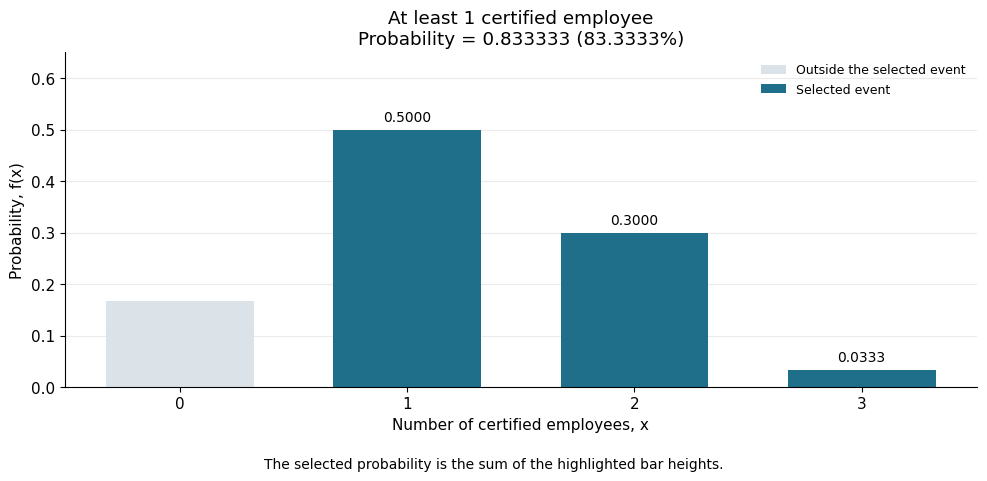

In [5]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def hypergeometric_probability_explorer():
    from math import comb
    from fractions import Fraction

    N, r, n = 10, 4, 3
    values = list(range(max(0, n-(N-r)), min(n, r)+1))
    total_groups = comb(N, n)
    counts = {x: comb(r, x)*comb(N-r, n-x) for x in values}
    probabilities = {x: counts[x]/total_groups for x in values}

    formulation = widgets.Dropdown(
        options=[
            ("At most k certified employees (k or fewer)", "le"),
            ("Fewer than k certified employees", "lt"),
            ("Exactly k certified employees", "eq"),
            ("At least k certified employees (k or more)", "ge"),
            ("More than k certified employees", "gt"),
            ("Between a and b certified employees (including both)", "between"),
            ("Outside a to b certified employees (below a or above b)", "outside"),
        ],
        value="ge", description="Event:",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="650px", max_width="100%"),
    )
    cutoff = widgets.IntSlider(
        value=1, min=0, max=n, description="Certified (k):",
        continuous_update=False, style={"description_width": "initial"},
    )
    interval = widgets.IntRangeSlider(
        value=(1, 2), min=0, max=n, description="Range (a, b):",
        continuous_update=False, style={"description_width": "initial"},
        layout=widgets.Layout(display="none"),
    )
    controls = widgets.VBox([formulation, cutoff, interval])
    display(controls)
    calculation_display = display(Markdown(""), display_id=True)
    graph_display = display(Markdown(""), display_id=True)

    def update(change=None):
        kind, k = formulation.value, cutoff.value
        a, b = interval.value
        is_range = kind in ("between", "outside")
        cutoff.layout.display = "none" if is_range else ""
        interval.layout.display = "" if is_range else "none"
        employee_word = "employee" if k == 1 else "employees"
        events = {
            "le": ([x for x in values if x <= k], rf"X\leq {k}",
                   f"At most {k} certified {employee_word}"),
            "lt": ([x for x in values if x < k], rf"X<{k}",
                   f"Fewer than {k} certified {employee_word}"),
            "eq": ([x for x in values if x == k], rf"X={k}",
                   f"Exactly {k} certified {employee_word}"),
            "ge": ([x for x in values if x >= k], rf"X\geq {k}",
                   f"At least {k} certified {employee_word}"),
            "gt": ([x for x in values if x > k], rf"X>{k}",
                   f"More than {k} certified {employee_word}"),
            "between": ([x for x in values if a <= x <= b],
                        rf"{a}\leq X\leq {b}",
                        f"Between {a} and {b} certified employees, inclusive"),
            "outside": ([x for x in values if x < a or x > b],
                        rf"X<{a}\ \mathrm{{or}}\ X>{b}",
                        f"Fewer than {a} or more than {b} certified employees"),
        }
        selected, event, title = events[kind]
        excluded = [x for x in values if x not in selected]
        exact_result = Fraction(sum(counts[x] for x in selected), total_groups)
        result = float(exact_result)
        use_complement = len(excluded) < len(selected)
        terms = excluded if use_complement else selected
        lines = [
            "### Hypergeometric Probabilities: Employees",
            "Beta Services: select 3 different employees at random from 10, "
            "of whom 4 are certified. No replacement.",
            r"$$N=10,\quad r=4,\quad n=3,\qquad "
            r"f(x)=\frac{\binom{4}{x}\binom{6}{3-x}}{\binom{10}{3}}.$$",
            title + ".",
        ]
        if not selected:
            lines.append("No possible count satisfies this event.")
        elif not excluded:
            lines.append("Every possible count satisfies this event.")
        else:
            symbolic_sum = "+".join(rf"f({x})" for x in terms)
            expression = rf"1-\left[{symbolic_sum}\right]" if use_complement else symbolic_sum
            lines.append(rf"$$P({event})={expression}.$$")
            if use_complement:
                lines.append("Subtract the probabilities of the excluded counts from one.")
            lines.extend([
                "",
                "| Certified employees, $x$ | Calculation of $f(x)$ | Probability |",
                "|---|---|---:|",
            ])
            for x in terms:
                formula = (rf"\frac{{\binom{{4}}{{{x}}}\binom{{6}}{{{3-x}}}}}"
                           rf"{{\binom{{10}}{{3}}}}"
                           rf"=\frac{{{comb(r, x)}({comb(N-r, n-x)})}}{{{total_groups}}}"
                           rf"=\frac{{{counts[x]}}}{{{total_groups}}}")
                lines.append(f"| {x} | $" + formula + f"$ | {probabilities[x]:.6f} |")
            numbers = "+".join(rf"\frac{{{counts[x]}}}{{{total_groups}}}" for x in terms)
            arithmetic = rf"1-\left[{numbers}\right]" if use_complement else numbers
            fraction = rf"\frac{{{exact_result.numerator}}}{{{exact_result.denominator}}}"
            lines.extend(["", rf"$$P({event})={arithmetic}={fraction}"
                          rf"\approx {result:.6f}\quad({100*result:.4f}\%).$$"])
        if not terms:
            lines.append(rf"$$P({event})={result:g}={100*result:g}\%.$$")
        calculation_display.update(Markdown("\n\n".join(lines[:4]) + "\n\n" +
                                            "\n".join(lines[4:])))

        with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                             "axes.spines.right": False}):
            fig, ax = plt.subplots(figsize=(10, 4.8))
            ax.bar(values, [probabilities[x] for x in values], width=0.65,
                   color="#dce3e8", label="Outside the selected event")
            if selected:
                bars = ax.bar(selected, [probabilities[x] for x in selected],
                              width=0.65, color="#1f6f8b", label="Selected event")
                ax.bar_label(bars, labels=[f"{probabilities[x]:.4f}" for x in selected],
                             padding=4, fontsize=10)
            ax.set(title=f"{title}\nProbability = {result:.6f} ({100*result:.4f}%)",
                   xlabel="Number of certified employees, x",
                   ylabel="Probability, f(x)", xticks=values, ylim=(0, 0.65))
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)
            ax.legend(frameon=False, fontsize=9, loc="upper right")
            fig.text(0.5, 0.01,
                     "The selected probability is the sum of the highlighted bar heights.",
                     ha="center", fontsize=10)
            fig.tight_layout(rect=(0, 0.05, 1, 1))
            graph_display.update(fig)
            plt.close(fig)

    for control in (formulation, cutoff, interval):
        control.observe(update, names="value")
    update()
    return controls

hypergeometric_controls = hypergeometric_probability_explorer()

### Hypergeometric Mean and Variance

For a sample of $n$ from a population of $N>1$ containing $r$ successes, let $p=r/N$.

$$E(X)=np=n\frac{r}{N}.$$

$$\operatorname{Var}(X)=np(1-p)\frac{N-n}{N-1},
\qquad \sigma=\sqrt{np(1-p)\frac{N-n}{N-1}}.$$

* $(N-n)/(N-1)$: correction for sampling without replacement
* For $1<n\leq N$ and $0<r<N$: variance below the corresponding binomial variance

For Beta Services:

$$\mu=3\left(\frac4{10}\right)=1.20\text{ certified employees},$$

$$\sigma^2=3\left(\frac4{10}\right)\left(\frac6{10}\right)
\left(\frac{10-3}{10-1}\right)=0.56\text{ employees}^2,$$

$$\sigma=\sqrt{0.56}\approx0.7483\text{ employees}.$$

If the whole population is selected, $n=N$ and $X=r$ with certainty; the variance is zero.

---

### Hypergeometric Mean and Variance

Beta Services: direct calculation from the complete probability distribution.

| $x$ | $f(x)$ | $xf(x)$ | $x^2f(x)$ |
|---|---:|---:|---:|
| 0 | $1/6$ | 0 | 0 |
| 1 | $1/2$ | $1/2$ | $1/2$ |
| 2 | $3/10$ | $6/10$ | $12/10$ |
| 3 | $1/30$ | $3/30$ | $9/30$ |
| Total | 1 | 1.20 | 2.00 |

$$E(X)=0+\frac12+\frac6{10}+\frac3{30}=1.20.$$

$$\operatorname{Var}(X)=E(X^2)-[E(X)]^2
=2.00-(1.20)^2=0.56.$$

* Mean of 1.20: long-run average across repeated random groups
* Not a possible count in a single group

---

### Sampling With and Without Replacement

Consider three random draws from ten items, four of which are labelled success.

| Feature | Replace and mix after every draw | Do not replace |
|---|---|---|
| Model | Binomial, $n=3,\ p=0.40$ | Hypergeometric, $N=10,\ r=4,\ n=3$ |
| Success probability after a success | $4/10$ | $3/9$ |
| Mean | $3(0.40)=1.20$ | $3(4/10)=1.20$ |
| Variance | $3(0.40)(0.60)=0.72$ | $0.72(7/9)=0.56$ |

* With replacement: independent draws; the same item can appear again.
* Without replacement: three different items selected.

$$P(X=0)\text{ with replacement}=(0.60)^3=0.216.$$

$$P(X=0)\text{ without replacement}
=\frac6{10}\frac5{9}\frac4{8}
=\frac{\binom6{3}}{\binom{10}{3}}
=\frac16\approx0.166667.$$

Equal means do not make the distributions interchangeable.

---

The mean is $\mu=nr/N$. Selecting a mean changes $r$; the menu lists only means possible for the current n and N.

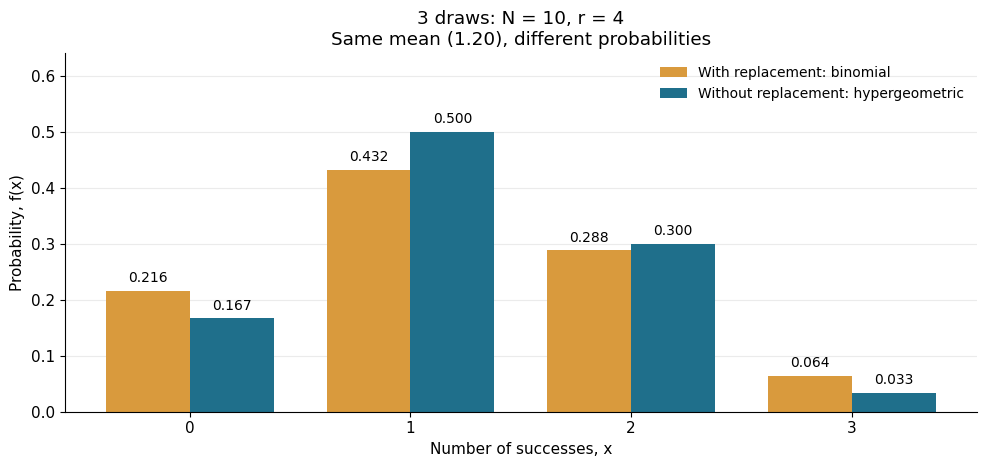

In [6]:
from math import comb
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def replacement_comparison():
    draws = widgets.BoundedIntText(
        value=3, min=1, max=10, description="Draws (n):",
        style={"description_width": "initial"},
    )
    population = widgets.BoundedIntText(
        value=10, min=1, max=200, description="Population (N):",
        style={"description_width": "initial"},
    )
    successes = widgets.BoundedIntText(
        value=4, min=0, max=10, description="Successes (r):",
        style={"description_width": "initial"},
    )
    mean = widgets.Dropdown(
        options=[(f"{3*j/10:.6g}", 3*j/10) for j in range(11)],
        value=1.2, description="Mean:",
        style={"description_width": "initial"},
    )
    controls = widgets.VBox([draws, population, successes, mean])
    display(controls)
    display(Markdown(
        r"The mean is $\mu=nr/N$. Selecting a mean changes $r$; "
        "the menu lists only means possible for the current n and N."
    ))
    graph_display = display(Markdown(""), display_id=True)
    updating = False

    def update(change=None):
        nonlocal updating
        if updating:
            return
        updating = True
        try:
            N = population.value
            # Bounded inputs keep 1 <= n <= N and 0 <= r <= N.
            draws.max = N
            successes.max = N
            n = draws.value
            if change is not None and change["owner"] is mean:
                successes.value = round(mean.value*N/n)
            r = successes.value
            attainable_means = [(f"{n*j/N:.6g}", n*j/N) for j in range(N+1)]
            mean.options = attainable_means
            mean.value = n*r/N
        finally:
            updating = False

        p = r/N
        mu = n*p
        x = list(range(n+1))
        binomial = [comb(n, k)*p**k*(1-p)**(n-k) for k in x]
        lower, upper = max(0, n-(N-r)), min(n, r)
        hypergeometric = [
            comb(r, k)*comb(N-r, n-k)/comb(N, n)
            if lower <= k <= upper else 0.0
            for k in x
        ]
        comparison = ("same probabilities" if n == 1 or r in (0, N)
                      else "different probabilities")

        with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                             "axes.spines.right": False}):
            fig, ax = plt.subplots(figsize=(10, 4.8))
            first = ax.bar([k-0.19 for k in x], binomial, width=0.38,
                           color="#d99a3d", label="With replacement: binomial")
            second = ax.bar([k+0.19 for k in x], hypergeometric, width=0.38,
                            color="#1f6f8b", label="Without replacement: hypergeometric")
            if n <= 6:
                for bars in (first, second):
                    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)
            ax.set(title=f"{n} draws: N = {N}, r = {r}\n"
                         f"Same mean ({mu:.2f}), {comparison}",
                   xlabel="Number of successes, x", ylabel="Probability, f(x)",
                   xticks=range(0, n+1, max(1, (n+9)//10)),
                   ylim=(0, 1.28*max(max(binomial), max(hypergeometric))))
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)
            ax.legend(frameon=False, fontsize=10, loc="upper right")
            fig.tight_layout()
            graph_display.update(fig)
            plt.close(fig)

    for control in (draws, population, successes, mean):
        control.observe(update, names="value")
    update()
    return controls

comparison_controls = replacement_comparison()

### Binomial Approximation to the Hypergeometric Distribution

* Small sample relative to the population: little change in success probability as items are removed.
* Binomial model with $p=r/N$: an approximation to the hypergeometric model under this condition.

Keep $n=3$ and $r/N=0.40$:

| Population, $N$ | Successes, $r$ | Sample fraction, $n/N$ | Exact $P(X=0)$ | Binomial $P(X=0)$ |
|---|---:|---:|---:|---:|
| 10 | 4 | 30% | 0.166667 | 0.216000 |
| 100 | 40 | 3% | 0.211626 | 0.216000 |
| 1,000 | 400 | 0.3% | 0.215567 | 0.216000 |

$$P(X=0)=\frac{\binom{N-r}{3}}{\binom{N}{3}},
\qquad P_{\mathrm{Bin}}(X=0)=(0.60)^3.$$

The variance correction also approaches one:

$$\frac{10-3}{10-1}=0.7778,\qquad
\frac{100-3}{100-1}=0.9798,\qquad
\frac{1000-3}{1000-1}=0.9980.$$

* Large population alone: insufficient if the sample fraction is also large.
* Use the exact model when population composition is given and the calculation is manageable.

---

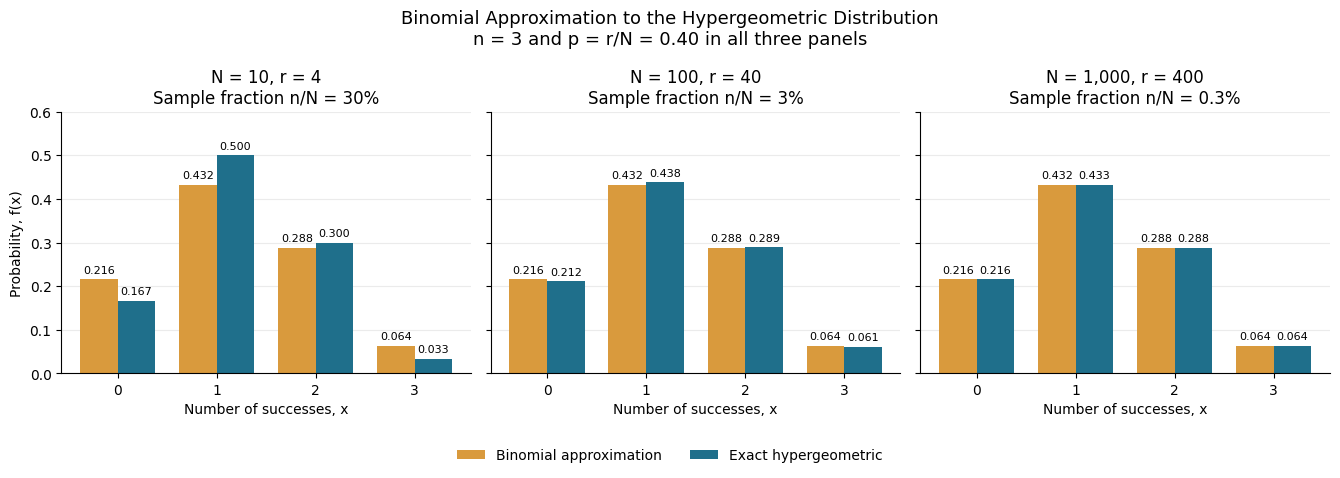

In [7]:
from math import comb
import matplotlib.pyplot as plt

def binomial_approximation_graph():
    n, p = 3, 0.40
    x = list(range(n+1))
    binomial = [comb(n, k)*p**k*(1-p)**(n-k) for k in x]
    populations = [(10, 4), (100, 40), (1000, 400)]

    with plt.rc_context({"font.size": 10, "axes.spines.top": False,
                         "axes.spines.right": False}):
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
        for ax, (N, r) in zip(axes, populations):
            exact = [comb(r, k)*comb(N-r, n-k)/comb(N, n) for k in x]
            first = ax.bar([k-0.19 for k in x], binomial, width=0.38,
                           color="#d99a3d", label="Binomial approximation")
            second = ax.bar([k+0.19 for k in x], exact, width=0.38,
                            color="#1f6f8b", label="Exact hypergeometric")
            for bars in (first, second):
                ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
            ax.set(title=f"N = {N:,}, r = {r:,}\nSample fraction n/N = {100*n/N:g}%",
                   xlabel="Number of successes, x", xticks=x, ylim=(0, 0.60))
            ax.grid(axis="y", alpha=0.25)
            ax.set_axisbelow(True)
        axes[0].set_ylabel("Probability, f(x)")
        fig.suptitle("Binomial Approximation to the Hypergeometric Distribution\n"
                     "n = 3 and p = r/N = 0.40 in all three panels", fontsize=13)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
                   bbox_to_anchor=(0.5, 0.01))
        fig.tight_layout(rect=(0, 0.10, 1, 1))
        plt.show()

binomial_approximation_graph()

### Exercise 6

Gamma Electronics evaluates an inspection plan for a lot containing exactly three defective items.

* Random sampling without replacement
* Every sample of the chosen size equally likely

| Lot size | Defective items | Candidate sample sizes |
|---:|---:|---|
| 12 | 3 | 2, 3, or 4 items |

The lot is rejected if the sample contains at least one defective item.

a. Choose the smallest candidate sample size that gives at least a 70% probability of rejecting this lot. Show the probabilities for all three candidates.

b. For the chosen sample size, calculate the mean and standard deviation of the number of defective items found.

c. What does an accepted sample establish about the uninspected items in this particular lot?

---

### Probability Distributions: Comparison

| Feature | Binomial | Poisson | Hypergeometric |
|---|---|---|---|
| What is counted? | Successes in $n$ trials | Occurrences in an interval | Successes in a sample of $n$ |
| Parameters | $n,p$ | Expected interval count, $\mu$ | $N,r,n$ |
| Key conditions | Independent trials, common $p$ | Constant rate, independent non-overlapping counts, individual occurrences | Random sampling without replacement from a fixed population |
| Possible values | $0,\ldots,n$ | $0,1,2,\ldots$ | $\max(0,n-N+r),\ldots,\min(n,r)$ |
| Mean | $np$ | $\mu$ | $nr/N$ |
| Variance | $np(1-p)$ | $\mu$ | $n(r/N)(1-r/N)(N-n)/(N-1)$ |

* Model choice: the random variable and the sampling or arrival process
* Different counting problems:
  * Defects among a fixed number of independently produced items
  * Flaws along a length of cable

---

### Probabilities in Excel

Last argument:

* FALSE: exact probability
* TRUE: cumulative probability $P(X\leq k)$

| Model and parameters | Exact probability $P(X=1)$ | At most one, $P(X\leq1)$ |
|---|---|---|
| Binomial: $n=5,\ p=0.40$ | `=BINOM.DIST(1,5,0.4,FALSE)` | `=BINOM.DIST(1,5,0.4,TRUE)` |
| Poisson: $\mu=3$ | `=POISSON.DIST(1,3,FALSE)` | `=POISSON.DIST(1,3,TRUE)` |
| Hypergeometric: $N=10,\ r=4,\ n=3$ | `=HYPGEOM.DIST(1,3,4,10,FALSE)` | `=HYPGEOM.DIST(1,3,4,10,TRUE)` |

Results, in the same column order:

* Binomial: $(0.259200,\ 0.336960)$
* Poisson: $(0.149361,\ 0.199148)$
* Hypergeometric: $(0.500000,\ 0.666667)$

For at least $k$, subtract the cumulative probability through $k-1$ from one. For example,

`=1-HYPGEOM.DIST(1,3,4,10,TRUE)`

gives $P(X\geq2)=1-0.666667=0.333333$.

* Argument separator: commas or semicolons, depending on the Excel installation
* POISSON.DIST: interval mean, not the hourly rate

---

### Exercise 7

Consider three counts recorded by Delta Services.

| Record | Process | Count of interest |
|---|---|---|
| A | Four customers decide independently; each buys with probability 0.20. | Customers who buy |
| B | Four different orders are randomly selected from 20 orders, exactly four of which require correction. | Selected orders requiring correction |
| C | Calls arrive at a constant rate of four per hour according to a Poisson process. | Calls in 30 minutes |

For each record, identify the distribution and its parameters, calculate the expected count, and find the probability of a count of at least two.

Could Records A and B use the same exact probability calculation because both involve four observations and a population proportion or success probability of 0.20? Explain using their selection processes.

---

### What is next?

* Week 7: Review and Midterm Exam
  * Descriptive Statistics
  * Probability
  * Discrete Probability Distributions
* Common Midterm Exam: 22 October 2026

---

### Exercise 8

Epsilon sells five one-year service contracts.

* At most one claim per contract
* Independent claims across contracts, with the same probability for each

| Contracts sold | Claim probability per contract | Payment per claim |
|---:|---:|---:|
| 5 | 0.10 | 200 MAD |

* Same premium per contract; all premiums received at the start
* No other revenues or costs
* Profit: total premiums minus total claim payments
* Breaking even is not a loss.

a. Find the smallest whole-MAD premium per contract that makes the probability of a loss no greater than 1%.

b. At that premium, calculate expected total profit and its standard deviation.

---

### Exercise 9

Zeta Support: a randomly selected 20-minute interval.

* One condition throughout the interval, initially unobserved
* Conditional on that condition: a Poisson process at the stated rate

| Condition | Probability | Call rate |
|---|---:|---:|
| Regular | 0.60 | 3 per hour |
| Busy | 0.40 | 9 per hour |

a. Find the probability of at least three calls in the interval.

b. The interval contains at least three calls, but the exact count is not reported. Find the probability that the condition was busy.

c. An analyst averages the two rates using the condition probabilities and uses that rate in a single Poisson model. Calculate the resulting probability of the event in part (a). Is it the same model?

---

### Exercise 10

Eta Imports receives lots of ten items. Supplier records establish the following lot composition before inspection:

| Lot type | Proportion of incoming lots | Defective items in the lot |
|---|---:|---:|
| A | 0.70 | 1 |
| B | 0.30 | 4 |

* Individual lot type: unknown
* Choice: randomly inspect three or four different items without replacement.
* Every sample of the chosen size equally likely
* Tests: perfect defect identification; no damage to items

The lot is accepted only if no defect is found.

| Cost | Amount |
|---|---:|
| Inspection | 6 MAD per sampled item |
| Additional charge if a Type B lot is accepted | 120 MAD per lot |
| Other costs for this comparison | 0 MAD |

Recommend one inspection plan. Support your recommendation with the acceptance probability, the probability that an accepted lot is Type B, and expected total cost per incoming lot. Explain the trade-off behind your choice.

---